# Constraint Satisfaction Problem : Graph coloring


## Create Data

We can create a planar graph with $n$ vertices by randomly placing $n$ points in 2-dimensional Euclidean space and then performing a [Delaunay triangulation](https://en.wikipedia.org/wiki/Delaunay_triangulation).

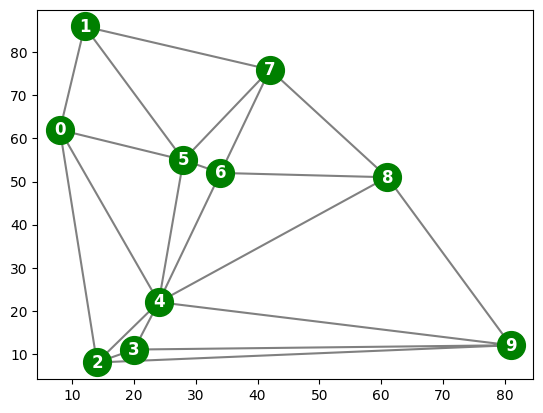

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial import Delaunay

np.random.seed(1111)

# create points and sort them by 
n = 10
points = np.random.randint(100, size=(n, 2))
o = np.argsort(points[:,0])
points = points[o,:]


# triangulate
tri = Delaunay(points)


# plot
plt.triplot(points[:,0], points[:,1], tri.simplices, color = "gray")
plt.plot(points[:,0], points[:,1], 'o', color = "green", markersize = 20)

for i in range(len(points)):
       plt.annotate(i, points[i,:], 
        color='white', fontsize="large", weight='heavy',
        horizontalalignment='center', verticalalignment='center')

plt.show()

The triangulation can be converted into a list with an array of neighbor vertex indices for each point (see man page for [scipy.spatial.Delaunay](https://docs.scipy.org/doc/scipy/reference/generated/scipy.spatial.Delaunay.html)). 

In [2]:
(indptr, indices) = tri.vertex_neighbor_vertices

neighbors = []

for k in range(len(indptr)-1):
    neighbors.append(np.sort(indices[indptr[k]:indptr[k+1]]))
    
neighbors

[array([1, 2, 4, 5], dtype=int32),
 array([0, 5, 7], dtype=int32),
 array([0, 3, 4, 9], dtype=int32),
 array([2, 4, 9], dtype=int32),
 array([0, 2, 3, 5, 6, 8, 9], dtype=int32),
 array([0, 1, 4, 6, 7], dtype=int32),
 array([4, 5, 7, 8], dtype=int32),
 array([1, 5, 6, 8], dtype=int32),
 array([4, 6, 7, 9], dtype=int32),
 array([2, 3, 4, 8], dtype=int32)]

The first row are the indices for the points neighboring point 0.

## Define CSP

The problem is defined as a dictionary with variable names, a dictionary with domain values for each variable and a set of binary  not-equal constraints (tuples of variables that are not allowed to have the same value).  

In [3]:
variables = [str(var) for var in range(n)]

domain = ['red', 'blue', 'green', 'orange']
#domain = ['red', 'blue', 'green']
domains = {}
for v in variables: 
    domains[v] = domain

# create binary constraints
constraints = {}
for i in range(len(neighbors)):
    for j in neighbors[i]:
        if(i<j): constraints[tuple([str(i), str(j)])] = True
constraints = constraints.keys()

csp = {'variables': variables, 'domains': domains, 'constraints': constraints, }
csp

{'variables': ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9'],
 'domains': {'0': ['red', 'blue', 'green', 'orange'],
  '1': ['red', 'blue', 'green', 'orange'],
  '2': ['red', 'blue', 'green', 'orange'],
  '3': ['red', 'blue', 'green', 'orange'],
  '4': ['red', 'blue', 'green', 'orange'],
  '5': ['red', 'blue', 'green', 'orange'],
  '6': ['red', 'blue', 'green', 'orange'],
  '7': ['red', 'blue', 'green', 'orange'],
  '8': ['red', 'blue', 'green', 'orange'],
  '9': ['red', 'blue', 'green', 'orange']},
 'constraints': dict_keys([('0', '1'), ('0', '2'), ('0', '4'), ('0', '5'), ('1', '5'), ('1', '7'), ('2', '3'), ('2', '4'), ('2', '9'), ('3', '4'), ('3', '9'), ('4', '5'), ('4', '6'), ('4', '8'), ('4', '9'), ('5', '6'), ('5', '7'), ('6', '7'), ('6', '8'), ('7', '8'), ('8', '9')])}

## Check Completeness and Consistency

`assignment` is a dictionary. Assigned variables have an entry with the variable name as the key. `{}` is therefore the empty assignment.

In [4]:
def complete(assignment, csp):
    return(all([v in assignment.keys() for v in csp['variables']])) 

print("complete({}, csp) =", complete({}, csp))

print("complete({...complete list...}, csp) =", 
      complete({'0': 'red', '1': 'red', '2': 'red', '3': 'red', '4': 'red', 
          '5': 'red', '6': 'red', '7': 'red', '8': 'red', '9': 'red'}, csp))

complete({}, csp) = False
complete({...complete list...}, csp) = True


In [5]:
def consistent(assignment, csp):
    for constr in csp['constraints']:
        if(constr[0] in assignment.keys() and constr[1] in assignment.keys()):
            if assignment[constr[0]] == assignment[constr[1]]: return(False)
        
    return(True)
        
print("consistent({}, csp) =", consistent({}, csp))
print("consistent({'0': 'red', '1': 'red', '2': 'blue'}, csp) =", 
      consistent({'0': 'red', '1': 'red', '2': 'blue'}, csp))

consistent({}, csp) = True
consistent({'0': 'red', '1': 'red', '2': 'blue'}, csp) = False


## Implement Simple Backtracking Search

In [6]:
# MRV: chọn biến chưa gán có ít giá trị hợp lệ nhất; nếu hòa, ưu tiên biến có nhiều láng giềng chưa gán hơn.
_NEIGHBOR_CACHE = {}

def _get_neighbor_map(csp):
    key = id(csp)
    if key not in _NEIGHBOR_CACHE or _NEIGHBOR_CACHE[key][0] is not csp:
        mapping = {v: set() for v in csp['variables']}
        for a, b in csp['constraints']:
            mapping[a].add(b)
            mapping[b].add(a)
        _NEIGHBOR_CACHE[key] = (csp, mapping)
    return _NEIGHBOR_CACHE[key][1]

def get_neighbors(var, csp):
    mapping = _get_neighbor_map(csp)
    return [v for v in csp['variables'] if v in mapping[var]]

def legal_values(var, assignment, csp, domains=None):
    available_domains = csp['domains'] if domains is None else domains
    result = []
    for value in available_domains[var]:
        allowed = True
        for neighbor in get_neighbors(var, csp):
            if neighbor in assignment and assignment[neighbor] == value:
                allowed = False
                break
        if allowed:
            result.append(value)
    return result

def select_unassigned_var(assignment, csp, domains=None, use_mrv=True):
    unassigned = [v for v in csp['variables'] if v not in assignment]
    if not unassigned:
        return None
    if not use_mrv:
        return unassigned[0]

    def mrv_key(var):
        remaining = len(legal_values(var, assignment, csp, domains))
        degree = sum(1 for neighbor in get_neighbors(var, csp)
                     if neighbor not in assignment)
        return (remaining, -degree, csp['variables'].index(var))

    return min(unassigned, key=mrv_key)

def order_domain(assignment, var, csp, domains=None):
    # LCV: thử màu loại bỏ ít lựa chọn nhất khỏi các láng giềng chưa gán trước.
    available_domains = csp['domains'] if domains is None else domains
    values = list(available_domains[var])

    def lcv_score(value):
        eliminated = 0
        for neighbor in get_neighbors(var, csp):
            if neighbor not in assignment and value in available_domains[neighbor]:
                eliminated += 1
        return eliminated

    return sorted(values, key=lambda value: (lcv_score(value), values.index(value)))

print("select_unassigned_var({'0': 'red', '1': 'blue'}, csp) =",
      select_unassigned_var({'0': 'red', '1': 'blue'}, csp))
print("Legal values for variable '2' with {'0': 'red', '1': 'blue'} =",
      legal_values('2', {'0': 'red', '1': 'blue'}, csp))

select_unassigned_var({'0': 'red', '1': 'blue'}, csp) = 5
Legal values for variable '2' with {'0': 'red', '1': 'blue'} = ['blue', 'green', 'orange']


In [7]:
# Verbose output is off by default so the search and experiments remain readable.
VERBOSE = False
COUNT = 0
ASSIGNMENT_ATTEMPTS = 0
SEARCH_ABORTED = False

def backtrack_search(csp, use_mrv=True, use_lcv=True, use_forward_checking=True,
                     max_nodes=None, show_stats=True):
    global COUNT, ASSIGNMENT_ATTEMPTS, SEARCH_ABORTED
    COUNT = 0
    ASSIGNMENT_ATTEMPTS = 0
    SEARCH_ABORTED = False
    initial_domains = {v: list(csp['domains'][v]) for v in csp['variables']}
    assignment = backtrack({}, csp, initial_domains, use_mrv, use_lcv,
                           use_forward_checking, max_nodes)
    if show_stats:
        print(f"Checked nodes: {COUNT}")
        print(f"Variable assignments attempted: {ASSIGNMENT_ATTEMPTS}")
        if SEARCH_ABORTED:
            print(f"Stopped at the node limit ({max_nodes}); this is not a proof of unsatisfiability.")
    return assignment

def backtrack(assignment, csp, domains=None, use_mrv=True, use_lcv=True,
              use_forward_checking=True, max_nodes=None):
    global VERBOSE, COUNT, ASSIGNMENT_ATTEMPTS, SEARCH_ABORTED

    if max_nodes is not None and COUNT >= max_nodes:
        SEARCH_ABORTED = True
        return None
    COUNT += 1

    if complete(assignment, csp):
        return assignment.copy() if consistent(assignment, csp) else None

    var = select_unassigned_var(assignment, csp, domains, use_mrv=use_mrv)
    if use_lcv:
        values = order_domain(assignment, var, csp, domains)
    else:
        values = list(domains[var])

    for val in values:
        if SEARCH_ABORTED:
            return None
        ASSIGNMENT_ATTEMPTS += 1
        assignment[var] = val

        if VERBOSE:
            print(f"Checking: {assignment}")

        if consistent(assignment, csp):
            branch_domains = {v: list(domains[v]) for v in csp['variables']}
            inference_failed = False

            if use_forward_checking:
                # Khi gán var = val, loại val khỏi miền của mọi láng giềng chưa gán.
                for neighbor in get_neighbors(var, csp):
                    if neighbor not in assignment and val in branch_domains[neighbor]:
                        branch_domains[neighbor].remove(val)
                        if len(branch_domains[neighbor]) == 0:
                            inference_failed = True
                            break

            if not inference_failed:
                result = backtrack(assignment, csp, branch_domains, use_mrv,
                                   use_lcv, use_forward_checking, max_nodes)
                if result is not None:
                    return result

        del assignment[var]
        if SEARCH_ABORTED:
            return None

    if VERBOSE:
        print("Backtracking")
    return None

## Run Backtracking Search on the Random Problem

In [8]:
%time res = backtrack_search(csp)
display(res)

Checked nodes: 11
Variable assignments attempted: 10
CPU times: user 436 μs, sys: 185 μs, total: 621 μs
Wall time: 621 μs


{'4': 'red',
 '5': 'blue',
 '0': 'green',
 '2': 'blue',
 '6': 'green',
 '7': 'red',
 '1': 'orange',
 '9': 'green',
 '3': 'orange',
 '8': 'blue'}

Plot the resulting coloring

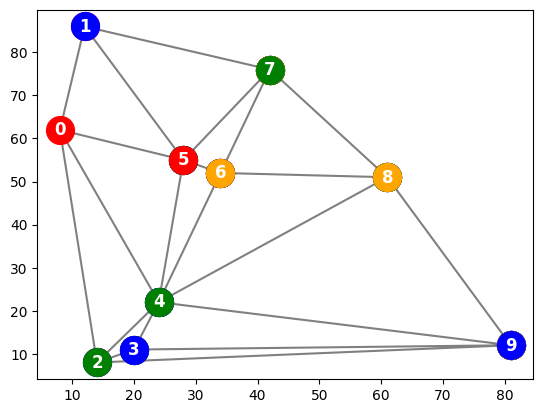

In [9]:
plt.triplot(points[:,0], points[:,1], tri.simplices, color = "gray")

for i in range(len(points)):
        plt.plot(points[i:,0], points[i:,1], 'o', color = list(res.values())[i], markersize = 20)
        plt.annotate(i, points[i,:], 
        color='white', fontsize="large", weight='heavy',
        horizontalalignment='center', verticalalignment='center')

plt.show()

## Assignment

Implement the following graph coloring algorithms:

* Add variable and value ordering to the implementation.
* Add forward checking to the implementation.
* Implement hill climbing local search with the min-conflicts heuristic.

Try to color graphs of several sizes with 3 and 4 colors. For each $n$, generate several random instances, and try to make n as large as you can manage. On average, how many constraints (edges) do your map coloring instances have for each $n$? Report the performance of each search algorithm as a function of $n$. For both variants of backtracking search, you can characterize performance in terms of the number of variable assignments attempted. For hill climbing search, report the number of uphill moves and random restarts required in order to reach a solution. Of course, you can also report raw running times as a function of $n$.

## Bài 1-2. Mô hình CSP và kiểm thử complete/consistent

- **Cấu trúc lưu:** `csp` là dictionary gồm `variables`, `domains` và `constraints`.
- **Biến (X):** các đỉnh của đồ thị, trong notebook được lưu bằng chuỗi `'0'`, `'1'`, ..., `'n-1'`.
- **Miền (D):** mỗi đỉnh nhận một màu trong `red`, `blue`, `green`, `orange` (hoặc chỉ 3 màu khi đổi miền).
- **Ràng buộc (C):** với mỗi cạnh vô hướng `(i, j)`, hai đỉnh phải có màu khác nhau. Chỉ lưu cạnh khi `i < j` để mỗi cạnh chỉ xuất hiện một lần; lưu cả `(i, j)` và `(j, i)` sẽ tạo ràng buộc trùng lặp không cần thiết.
- `complete(assignment, csp)` chỉ kiểm tra mọi biến đã được gán. `consistent(assignment, csp)` kiểm tra các ràng buộc giữa những đỉnh đã gán. Nghiệm CSP phải **vừa đầy đủ vừa nhất quán**.

In [10]:
# Các ca kiểm thử; kết quả thực tế được so sánh với kết quả mong đợi.
edge = next(iter(csp['constraints']))
empty_assignment = {}
one_vertex_assignment = {csp['variables'][0]: 'red'}
adjacent_same_color = {edge[0]: 'red', edge[1]: 'red'}
complete_but_invalid = {v: 'red' for v in csp['variables']}

csp_tests = [
    ("Phép gán rỗng", empty_assignment, False, True),
    ("Phép gán một phần", one_vertex_assignment, False, True),
    ("Phép gán đầy đủ hợp lệ", res, True, True),
    ("Hai đỉnh kề cùng màu", adjacent_same_color, False, False),
    ("Đầy đủ nhưng tất cả cùng màu", complete_but_invalid, True, False),
]

for name, assignment, expected_complete, expected_consistent in csp_tests:
    actual_complete = complete(assignment, csp)
    actual_consistent = consistent(assignment, csp)
    print(f"{name}: complete={actual_complete} (mong đợi {expected_complete}), "
          f"consistent={actual_consistent} (mong đợi {expected_consistent})")
    assert actual_complete == expected_complete
    assert actual_consistent == expected_consistent

print("Tất cả ca kiểm thử đều đạt.")

Phép gán rỗng: complete=False (mong đợi False), consistent=True (mong đợi True)
Phép gán một phần: complete=False (mong đợi False), consistent=True (mong đợi True)
Phép gán đầy đủ hợp lệ: complete=True (mong đợi True), consistent=True (mong đợi True)
Hai đỉnh kề cùng màu: complete=False (mong đợi False), consistent=False (mong đợi False)
Đầy đủ nhưng tất cả cùng màu: complete=True (mong đợi True), consistent=False (mong đợi False)
Tất cả ca kiểm thử đều đạt.


## Bài 3-4. Min-Conflicts và hàm hỗ trợ thí nghiệm

Min-Conflicts bắt đầu từ một phép gán đầy đủ ngẫu nhiên. Mỗi bước chọn một đỉnh đang xung đột rồi gán màu làm giảm số cạnh vi phạm nhiều nhất. Vì đây là tìm kiếm cục bộ, thuật toán có thể không tìm được nghiệm dù nghiệm tồn tại; do đó thí nghiệm dùng giới hạn bước và khởi động lại. Với Backtracking, `COUNT` là số nút tìm kiếm đã kiểm tra, còn `ASSIGNMENT_ATTEMPTS` là số lần thử gán một màu.

In [11]:
def count_conflicts(assignment, csp):
    """Đếm số cạnh có hai đầu cùng màu."""
    return sum(1 for a, b in csp['constraints']
               if a in assignment and b in assignment and assignment[a] == assignment[b])

def min_conflicts_search(csp, max_steps=1500, max_restarts=5, seed=None):
    rng = np.random.default_rng(seed)
    variables = csp['variables']
    best_assignment = None
    best_conflict_count = float('inf')
    total_steps = 0

    for restart_index in range(max_restarts + 1):
        assignment = {
            var: rng.choice(csp['domains'][var])
            for var in variables
        }

        for step in range(max_steps + 1):
            current_conflicts = count_conflicts(assignment, csp)
            if current_conflicts < best_conflict_count:
                best_conflict_count = current_conflicts
                best_assignment = assignment.copy()
            if current_conflicts == 0:
                return {
                    'assignment': assignment.copy(), 'success': True,
                    'steps': total_steps, 'restarts': restart_index,
                    'conflicts': 0
                }
            if step == max_steps:
                break

            conflicted_vars = [
                var for var in variables
                if any(assignment[var] == assignment[neighbor]
                       for neighbor in get_neighbors(var, csp))
            ]
            if not conflicted_vars:
                break

            var = rng.choice(conflicted_vars)
            neighbors = get_neighbors(var, csp)
            scores = {
                color: sum(1 for neighbor in neighbors
                           if assignment[neighbor] == color)
                for color in csp['domains'][var]
            }
            minimum_score = min(scores.values())
            best_colors = [color for color, score in scores.items()
                           if score == minimum_score]
            assignment[var] = rng.choice(best_colors)
            total_steps += 1

    return {
        'assignment': best_assignment, 'success': False,
        'steps': total_steps, 'restarts': max_restarts,
        'conflicts': int(best_conflict_count)
    }

def make_graph_csp(n_vertices, n_colors, seed):
    """Sinh đồ thị Delaunay tái lập được và tạo CSP với 3 hoặc 4 màu."""
    rng = np.random.RandomState(seed)
    for _ in range(20):
        raw_points = rng.randint(100, size=(n_vertices, 2))
        if len(np.unique(raw_points, axis=0)) != n_vertices:
            continue
        order = np.argsort(raw_points[:, 0])
        graph_points = raw_points[order, :]
        try:
            triangulation = Delaunay(graph_points)
            break
        except Exception:
            continue
    else:
        raise ValueError(f"Không tạo được tam giác hóa Delaunay cho n={n_vertices}, seed={seed}.")

    indptr, indices = triangulation.vertex_neighbor_vertices
    neighbor_lists = [np.sort(indices[indptr[k]:indptr[k + 1]])
                      for k in range(len(indptr) - 1)]
    variables = [str(v) for v in range(n_vertices)]
    all_colors = ['red', 'blue', 'green', 'orange']
    chosen_colors = all_colors[:n_colors]
    edges = []
    for i, neighbors_i in enumerate(neighbor_lists):
        for j in neighbors_i:
            if i < j:
                edges.append((str(i), str(j)))

    domains = {var: list(chosen_colors) for var in variables}
    graph_csp = {
        'variables': variables,
        'domains': domains,
        'constraints': tuple(edges)
    }
    return graph_csp, graph_points, triangulation

# Kiểm tra nhanh Min-Conflicts trên đồ thị mẫu đã tạo ở đầu notebook.
mc_demo = min_conflicts_search(csp, max_steps=2000, max_restarts=10, seed=2026)
print("Min-Conflicts success:", mc_demo['success'])
print("Best conflict count:", mc_demo['conflicts'])
print("Steps:", mc_demo['steps'], "| Restarts:", mc_demo['restarts'])
if mc_demo['assignment'] is not None:
    print("Consistent assignment:", consistent(mc_demo['assignment'], csp))

Min-Conflicts success: True
Best conflict count: 0
Steps: 3 | Restarts: 0
Consistent assignment: True


## Thí nghiệm: so sánh 3 màu và 4 màu theo kích thước đồ thị

Mỗi kích thước được thử trên 3 seed để tạo nhiều đồ thị ngẫu nhiên. Hai biến thể Backtracking được so sánh: bản cơ sở (thứ tự biến/giá trị ban đầu, không Forward Checking) và bản MRV + LCV + Forward Checking. Min-Conflicts dùng tối đa 1.500 bước cho mỗi lần khởi động và tối đa 5 lần khởi động lại. Backtracking bị giới hạn số nút để tránh một trường hợp 3 màu không có nghiệm làm notebook chạy quá lâu; trường hợp chạm giới hạn được ghi riêng, **không** kết luận là vô nghiệm.

In [12]:
import pandas as pd
import time

experiment_sizes = [10, 15, 20, 25]
experiment_seeds = [1111, 2222, 3333]
color_counts = [3, 4]
baseline_node_limit = 2500
optimized_node_limit = 12000
min_conflicts_steps = 1500
min_conflicts_restarts = 5

experiment_rows = []
edge_rows = []

for n_vertices in experiment_sizes:
    for seed in experiment_seeds:
        # Cả hai số màu dùng cùng đồ thị cho cùng n và seed.
        graph4, graph_points, graph_tri = make_graph_csp(n_vertices, 4, seed)
        edge_rows.append({
            'n': n_vertices, 'seed': seed,
            'edges': len(graph4['constraints'])
        })

        for n_colors in color_counts:
            graph_csp, _, _ = make_graph_csp(n_vertices, n_colors, seed)

            # Backtracking cơ sở: biến đầu tiên, thứ tự màu gốc, không suy diễn.
            start = time.perf_counter()
            basic_result = backtrack_search(
                graph_csp, use_mrv=False, use_lcv=False,
                use_forward_checking=False, max_nodes=baseline_node_limit,
                show_stats=False
            )
            basic_time = time.perf_counter() - start
            basic_nodes = COUNT
            basic_attempts = ASSIGNMENT_ATTEMPTS
            basic_limited = SEARCH_ABORTED
            experiment_rows.append({
                'n': n_vertices, 'colors': n_colors, 'seed': seed,
                'edges': len(graph_csp['constraints']),
                'algorithm': 'Backtracking cơ sở',
                'success': basic_result is not None,
                'limit_reached': basic_limited,
                'nodes': basic_nodes, 'assignments': basic_attempts,
                'steps': np.nan, 'restarts': np.nan,
                'time_s': basic_time,
                'final_conflicts': (count_conflicts(basic_result, graph_csp)
                                    if basic_result is not None else np.nan)
            })

            # Backtracking cải tiến: MRV + LCV + Forward Checking.
            start = time.perf_counter()
            optimized_result = backtrack_search(
                graph_csp, use_mrv=True, use_lcv=True,
                use_forward_checking=True, max_nodes=optimized_node_limit,
                show_stats=False
            )
            optimized_time = time.perf_counter() - start
            optimized_nodes = COUNT
            optimized_attempts = ASSIGNMENT_ATTEMPTS
            optimized_limited = SEARCH_ABORTED
            experiment_rows.append({
                'n': n_vertices, 'colors': n_colors, 'seed': seed,
                'edges': len(graph_csp['constraints']),
                'algorithm': 'MRV + LCV + FC',
                'success': optimized_result is not None,
                'limit_reached': optimized_limited,
                'nodes': optimized_nodes, 'assignments': optimized_attempts,
                'steps': np.nan, 'restarts': np.nan,
                'time_s': optimized_time,
                'final_conflicts': (count_conflicts(optimized_result, graph_csp)
                                    if optimized_result is not None else np.nan)
            })

            # Min-Conflicts: thuật toán ngẫu nhiên, có giới hạn bước và restart.
            start = time.perf_counter()
            mc_result = min_conflicts_search(
                graph_csp, max_steps=min_conflicts_steps,
                max_restarts=min_conflicts_restarts,
                seed=seed + 100000 + n_colors
            )
            mc_time = time.perf_counter() - start
            experiment_rows.append({
                'n': n_vertices, 'colors': n_colors, 'seed': seed,
                'edges': len(graph_csp['constraints']),
                'algorithm': 'Min-Conflicts',
                'success': mc_result['success'],
                'limit_reached': False,
                'nodes': np.nan, 'assignments': np.nan,
                'steps': mc_result['steps'], 'restarts': mc_result['restarts'],
                'time_s': mc_time,
                'final_conflicts': mc_result['conflicts']
            })

edge_df = pd.DataFrame(edge_rows)
results_df = pd.DataFrame(experiment_rows)

edge_summary = (edge_df.groupby('n', as_index=False)
                .agg(avg_edges=('edges', 'mean'), min_edges=('edges', 'min'),
                     max_edges=('edges', 'max'), graph_instances=('edges', 'count')))
performance_summary = (results_df.groupby(['n', 'colors', 'algorithm'], as_index=False)
    .agg(avg_edges=('edges', 'mean'),
         success_rate=('success', 'mean'),
         limited_runs=('limit_reached', 'sum'),
         avg_nodes=('nodes', 'mean'),
         avg_assignments=('assignments', 'mean'),
         avg_steps=('steps', 'mean'),
         avg_restarts=('restarts', 'mean'),
         avg_time_s=('time_s', 'mean'),
         avg_final_conflicts=('final_conflicts', 'mean'),
         trials=('success', 'count')))
performance_summary['success_rate_pct'] = performance_summary['success_rate'] * 100

print("Số cạnh trung bình theo kích thước (3 seed cho mỗi n):")
display(edge_summary.round(2))

backtracking_summary = performance_summary[
    performance_summary['algorithm'] != 'Min-Conflicts'
][['n', 'colors', 'algorithm', 'avg_edges', 'success_rate_pct',
   'limited_runs', 'avg_nodes', 'avg_assignments', 'avg_time_s', 'trials']]
min_conflicts_summary = performance_summary[
    performance_summary['algorithm'] == 'Min-Conflicts'
][['n', 'colors', 'success_rate_pct', 'avg_steps', 'avg_restarts',
   'avg_time_s', 'avg_final_conflicts', 'trials']]

print("Backtracking: trung bình theo 3 seed; COUNT là số nút, assignments là số lần thử gán màu.")
display(backtracking_summary.round(3))
print("Min-Conflicts: bước/restart trung bình theo 3 seed; final_conflicts là số cạnh còn xung đột ở trạng thái tốt nhất.")
display(min_conflicts_summary.round(3))

print("Ghi chú: Số lượt chạm giới hạn được thể hiện ở limited_runs; các lượt này không chứng minh bài toán vô nghiệm.")

Số cạnh trung bình theo kích thước (3 seed cho mỗi n):


,n,avg_edges,min_edges,max_edges,graph_instances
0,10,20.67,19,22,3
1,15,34.67,34,35,3
2,20,48.00,47,49,3
3,25,62.00,61,64,3


Backtracking: trung bình theo 3 seed; COUNT là số nút, assignments là số lần thử gán màu.


,n,colors,algorithm,avg_edges,success_rate_pct,limited_runs,avg_nodes,avg_assignments,avg_time_s,trials
0,10,3,Backtracking cơ sở,20.667,0.0,0,62.000,186.000,0.000,3
1,10,3,MRV + LCV + FC,20.667,0.0,0,26.000,31.000,0.001,3
3,10,4,Backtracking cơ sở,20.667,100.0,0,11.333,24.000,0.000,3
4,10,4,MRV + LCV + FC,20.667,100.0,0,11.000,10.000,0.000,3
6,15,3,Backtracking cơ sở,34.667,0.0,0,94.000,282.000,0.001,3
7,15,3,MRV + LCV + FC,34.667,0.0,0,28.000,33.000,0.001,3
9,15,4,Backtracking cơ sở,34.667,100.0,0,18.667,45.667,0.000,3
10,15,4,MRV + LCV + FC,34.667,100.0,0,16.000,15.000,0.001,3
12,20,3,Backtracking cơ sở,48.000,0.0,0,154.000,462.000,0.002,3
13,20,3,MRV + LCV + FC,48.000,0.0,0,32.000,37.000,0.003,3


Min-Conflicts: bước/restart trung bình theo 3 seed; final_conflicts là số cạnh còn xung đột ở trạng thái tốt nhất.


,n,colors,success_rate_pct,avg_steps,avg_restarts,avg_time_s,avg_final_conflicts,trials
2,10,3,0.0,9000.000,5.0,0.246,1.333,3
5,10,4,100.0,5.667,0.0,0.000,0.000,3
8,15,3,0.0,9000.000,5.0,0.337,2.333,3
11,15,4,100.0,20.000,0.0,0.001,0.000,3
14,20,3,0.0,9000.000,5.0,0.470,3.000,3
17,20,4,100.0,54.333,0.0,0.003,0.000,3
20,25,3,0.0,9000.000,5.0,0.573,4.333,3
23,25,4,100.0,50.333,0.0,0.003,0.000,3


Ghi chú: Số lượt chạm giới hạn được thể hiện ở limited_runs; các lượt này không chứng minh bài toán vô nghiệm.


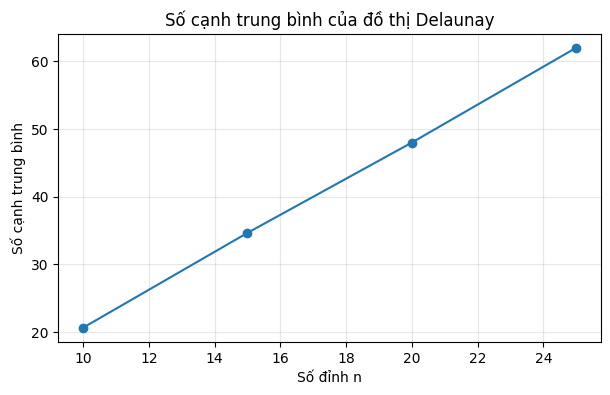

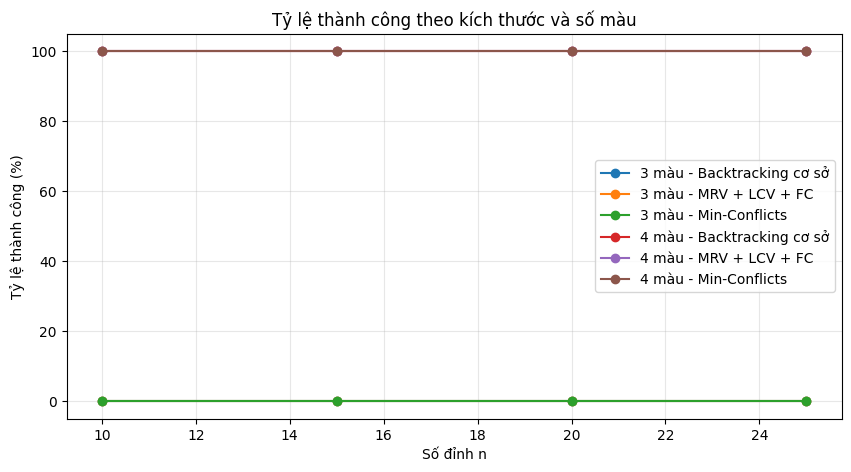

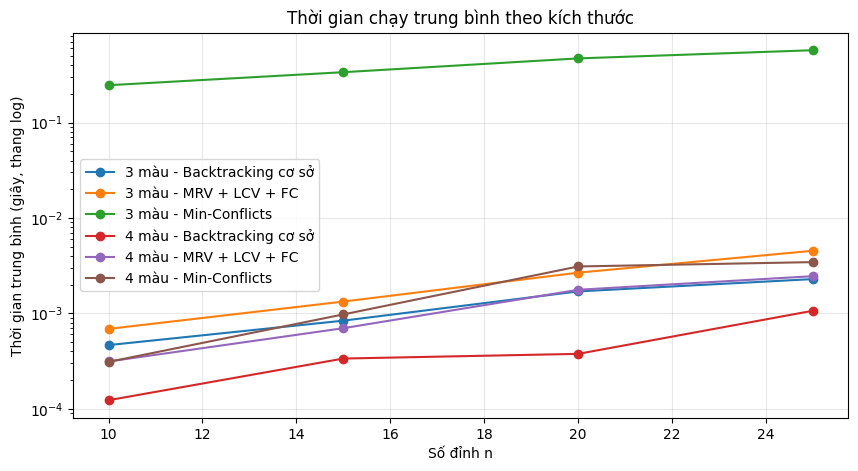

In [13]:
# Biểu đồ 1: số cạnh trung bình theo kích thước đồ thị.
plt.figure(figsize=(7, 4))
plt.plot(edge_summary['n'], edge_summary['avg_edges'], marker='o')
plt.xlabel('Số đỉnh n')
plt.ylabel('Số cạnh trung bình')
plt.title('Số cạnh trung bình của đồ thị Delaunay')
plt.grid(True, alpha=0.3)
plt.show()

# Biểu đồ 2: tỷ lệ tìm được nghiệm của từng thuật toán.
plt.figure(figsize=(10, 5))
for (n_colors, algorithm), group in performance_summary.groupby(['colors', 'algorithm']):
    group = group.sort_values('n')
    plt.plot(group['n'], group['success_rate_pct'], marker='o',
             label=f"{n_colors} màu - {algorithm}")
plt.xlabel('Số đỉnh n')
plt.ylabel('Tỷ lệ thành công (%)')
plt.title('Tỷ lệ thành công theo kích thước và số màu')
plt.ylim(-5, 105)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

# Biểu đồ 3: thời gian chạy trung bình; trục y log để thấy khác biệt về quy mô.
plt.figure(figsize=(10, 5))
for (n_colors, algorithm), group in performance_summary.groupby(['colors', 'algorithm']):
    group = group.sort_values('n')
    positive = group['avg_time_s'] > 0
    plt.plot(group.loc[positive, 'n'], group.loc[positive, 'avg_time_s'],
             marker='o', label=f"{n_colors} màu - {algorithm}")
plt.xlabel('Số đỉnh n')
plt.ylabel('Thời gian trung bình (giây, thang log)')
plt.title('Thời gian chạy trung bình theo kích thước')
plt.yscale('log')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

## Minh họa lời giải tô màu và trả lời câu hỏi thảo luận liên quan

Biểu đồ dưới đây vẽ mỗi đỉnh một lần theo màu của lời giải tìm được, nếu Backtracking cải tiến tìm được nghiệm trên đồ thị mẫu ban đầu.

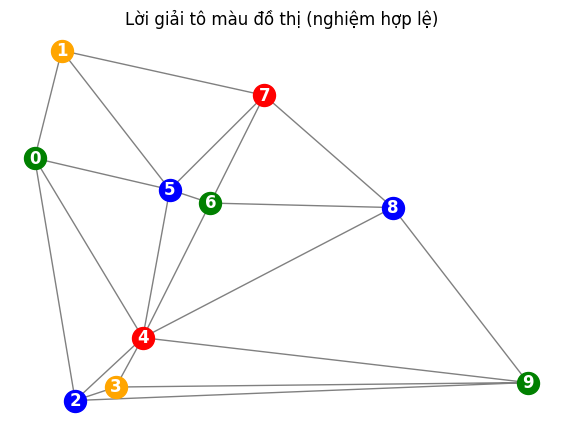

Kiểm tra lời giải mẫu:
complete = True
consistent = True
Số ràng buộc/cạnh = 21


In [14]:
if res is not None and consistent(res, csp) and complete(res, csp):
    plt.figure(figsize=(7, 5))
    plt.triplot(points[:, 0], points[:, 1], tri.simplices, color='gray', linewidth=1)
    for i in range(len(points)):
        plt.scatter(points[i, 0], points[i, 1], color=res[str(i)], s=250, zorder=3)
        plt.annotate(i, points[i, :], color='white', fontsize='large', weight='bold',
                     horizontalalignment='center', verticalalignment='center', zorder=4)
    plt.title('Lời giải tô màu đồ thị (nghiệm hợp lệ)')
    plt.axis('off')
    plt.show()
else:
    print("Không có nghiệm hợp lệ để vẽ trên đồ thị mẫu.")

print("Kiểm tra lời giải mẫu:")
print("complete =", complete(res, csp) if res is not None else False)
print("consistent =", consistent(res, csp) if res is not None else False)
print("Số ràng buộc/cạnh =", len(csp['constraints']))

### Câu 1. Khác nhau giữa `complete()` và `consistent()`

`complete()` chỉ cho biết tất cả biến đã có giá trị; `consistent()` chỉ ra phép gán hiện tại chưa vi phạm ràng buộc giữa các biến đã gán. Phép gán đầy đủ không luôn là nghiệm CSP: ví dụ gán tất cả đỉnh cùng màu là đầy đủ nhưng không nhất quán nếu đồ thị có cạnh. Nghiệm CSP phải thỏa mãn cả hai điều kiện.

### Câu 2. MRV và Forward Checking ảnh hưởng thế nào?

MRV chọn biến có ít giá trị hợp lệ còn lại nhất, giúp phát hiện nhánh bế tắc sớm. Forward Checking loại màu vừa dùng khỏi miền của các đỉnh kề chưa gán và quay lui ngay khi miền nào đó rỗng. Chúng thường giảm số nhánh/nút phải tìm, nhưng việc tính miền hợp lệ, sao chép miền và cập nhật miền cũng tạo chi phí phụ; với bài toán nhỏ hoặc khi nhánh bị cắt ít, chi phí này có thể làm thời gian chạy không giảm tương ứng.

### Câu 3. Vì sao tô màu 3 màu có thể thất bại?

Đồ thị phẳng không phải lúc nào cũng tô được bằng 3 màu; định lý bốn màu chỉ bảo đảm tối đa 4 màu cho đồ thị phẳng. Nếu Backtracking duyệt hết mọi nhánh mà không có nghiệm thì có thể kết luận CSP đó vô nghiệm với miền màu đã chọn. Nếu dừng do giới hạn nút/thời gian thì chỉ biết chưa tìm được nghiệm trong ngân sách tính toán, không thể kết luận vô nghiệm.

### Câu 6. Vì sao phải chạy nhiều lần và cố định điều kiện thí nghiệm?

Đồ thị được sinh ngẫu nhiên và Min-Conflicts có lựa chọn ngẫu nhiên, nên một seed có thể tạo kết quả thuận lợi hoặc bất lợi. Dùng nhiều seed, cùng kích thước/số màu/giới hạn bước và ghi rõ tiêu chí dừng giúp so sánh công bằng hơn. Các số liệu trong notebook là kết quả thực nghiệm với 3 seed mỗi cấu hình, không phải bảo đảm tổng quát cho mọi đồ thị.